In [1]:
#lindblad_resonance.ipynb
#by Joe Hahn and Claude Code, joe.hahn@jmh-datasciences.com, 23 November 2026.
#massless particles at an m = 2 satellite's inner Lindblad resonance (paper Section 4.2.3), the in-plane counterpart of
#vertical_resonance.ipynb: 80 streamlines straddle r_L, the two nearest at x = +-2.5e-4. The paper shows no figure of
#this test; it quotes the agreement found here.
#test 9: D = kappa_a^2 - omega_m^2 (Eqn. (40)), at each streamline's semimajor axis, changes sign between the two
#        streamlines beside r_L, where the eccentricities peak; the eccentricities follow the forced eccentricity e_f of
#        Eqn. (47), to O(x); and every streamline's eccentricity e(t) settles as the satellite grows
#how each quantity is computed, straight from the simulation's output (load3d: every particle's r, theta, v_r, v_theta),
#with the paper's equations:
#  a, e   semimajor axis and eccentricity, the epicyclic elements of Section 2, "Coordinates to elements"
#  x      fractional distance from resonance, (a - r_L)/r_L
#  D      kappa_a^2 - omega_m^2, Eqn. (40): kappa_a and Omega_a (Eqn. 8) at a, omega_m = m(Omega_a - Omega_p),
#         Omega_p = Omega_{a_s} the satellite's pattern speed
#  <>     averaged over a streamline's particles and the outputs after t = 6 tau (late_outputs), once the satellite is grown
#  e_f    the forced eccentricity of Eqn. (47), the theory the eccentricities are compared with

In [2]:
#paths and imports
import sys
sys.path.insert(0, '../../source')
sys.path.insert(0, '../../fast')
sys.path.insert(0, '..')
import numpy as np

from density_analysis import load3d, resonance_D, late_outputs, satellite

In [3]:
#restore the simulation's output, and convert to elements
p, o = load3d('.')
sat = satellite(p)
print('r.shape = ', o['r'].shape)
for k in ('number_of_streamlines', 'particles_per_streamline', 'dt', 'J2', 'Rp', 'total_ring_mass'):
    print(k, '=', p[k])
for k, v in sat.summary().items():
    print(k, '=', v)
print('eccentricity range = ', o['e'].min(), o['e'].max())
print('monitor = ', o['monitor'])

r.shape =  (400, 80, 6)
number_of_streamlines = 80
particles_per_streamline = 6
dt = 0.5
J2 = 0.01
Rp = 0.5
total_ring_mass = 0.0
resonance = horizontal
m = 2
mass_final = 1e-08
time_grow = 100000.0
r = 1.6141146120822665
t = 0.0
Omega_a = 0.48798982846525035
nu_a = 0.4886906975272764
Omega_p = 0.48798982846525035
r_L = 1.0200000000000002
beta_L = 0.6319253864409066
b_12 = 0.36819265186251454
db_12 = 1.4698912766952985
Psi_per_mass = -1.491189183905236
Psi_final = -1.491189183905236e-08
D_L = 2.857449810655058
eccentricity range =  6.048340971099059e-09 2.077442787163731e-05
monitor =  {'start_time': 1795471271, 'current_time': 1795471601, 'current_timestep': 2000000, 'streamline_crossing_timestep': None, 'nan_timestep': None, 'self_interacting': False, 'modified_params': None}


In [4]:
#timescales: the satellite's mass grows as M_s(1 - exp(-t/tau)), the run lasts 10 tau, and the comparisons average
#over the outputs after t = 6 tau (late_outputs), once the satellite is grown, as the paper does
orbits = o['times']/(2.0*np.pi)
print('tau (orbits) = ', np.round(p['satellite']['time_grow']/(2.0*np.pi), 1))
print('run length (orbits) = ', np.round(orbits[-1], 1))

tau (orbits) =  15915.5
run length (orbits) =  159154.9


In [5]:
#prep plots
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
color_seq = plt.rcParams['axes.prop_cycle'].by_key()['color']
sns.set(font_scale=0.9, font='DejaVu Sans')

D = 0 at x =  2.1682327781781183e-07 , between the streamlines at x =  -0.0002482013033052493  and  0.00024819978551000784
the two largest eccentricities are at x =  [-0.0002482  0.0002482]
<e>/e_f ranges from  0.9392  to  1.0437 : largest |<e>/e_f - 1| =  6.08 %
   at x =  -0.01961


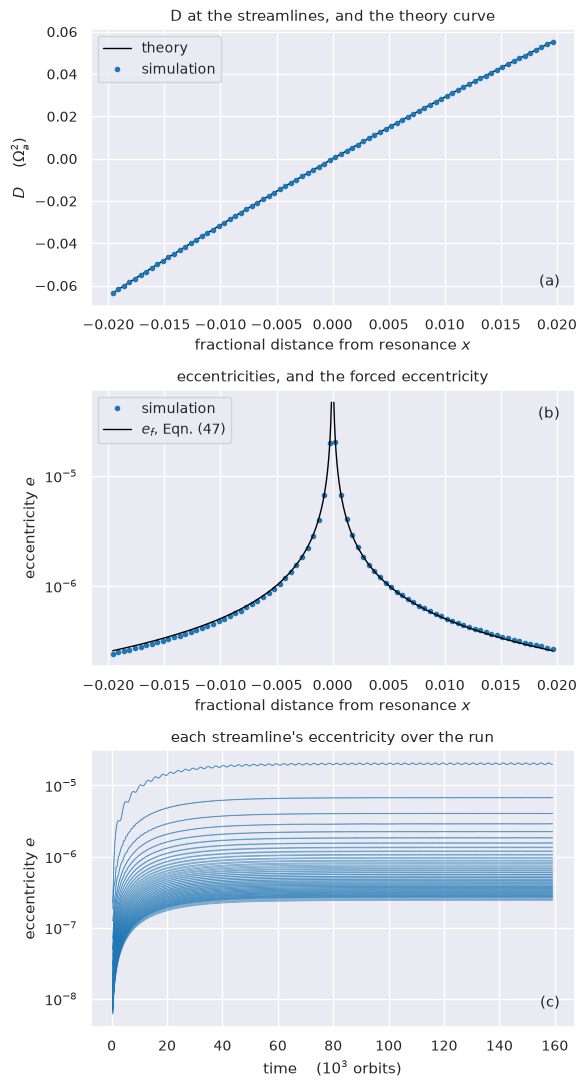

In [6]:
#test 9: (a) D = kappa_a^2 - omega_m^2 (Eqn. (40)), omega_m = m(Omega_a - Omega_p), at each streamline's semimajor
#axis a, averaged over its particles and the outputs after t = 6 tau, in units of Omega_a^2 at r_L; (b) each streamline's
#eccentricity, averaged the same way, versus the forced eccentricity
#e_f = (M_s/M_p) beta |beta db/dbeta + 2m b|/[3(m - 1)|x|] of Eqn. (47), which neglects terms of order x. D changes
#sign between the two streamlines beside r_L, which have the largest eccentricities. (c) every streamline's
#eccentricity e(t), averaged over its particles, as the satellite's mass grows as M_s(1 - exp(-t/tau))
late = late_outputs(p, o)
e_avg = o['e'][late].mean(axis=(0, 2))
x_avg = ((o['a'][late] - sat.r_L)/sat.r_L).mean(axis=(0, 2))
D = resonance_D(p, sat.r_L*(1 + x_avg))[1]
def e_forced(x):
    return sat.mass_final*sat.beta_L*abs(sat.beta_L*sat.db + 2*sat.m*sat.b)/(3*(sat.m - 1)*np.abs(x))
Omega_L2 = (1.0/sat.r_L**3)*(1 + 1.5*p['J2']*(p['Rp']/sat.r_L)**2)
f, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(6, 11))
xs = np.linspace(x_avg.min(), x_avg.max(), 2000)
ax1.plot(xs, resonance_D(p, sat.r_L*(1 + xs))[1]/Omega_L2, color='black', linewidth=1, label='theory')
ax1.plot(x_avg, D/Omega_L2, marker='o', markersize=3, linestyle='none', color=color_seq[0], label='simulation')
ax1.set_xlabel(r'fractional distance from resonance $x$')
ax1.set_ylabel(r'$D$    ($\Omega_a^2$)')
ax1.legend(loc='upper left')
ax2.plot(x_avg, e_avg, marker='o', markersize=3, linestyle='none', color=color_seq[0], label='simulation')
xs = xs[np.abs(xs) > 1.0e-4]
ax2.plot(xs[xs < 0], e_forced(xs[xs < 0]), color='black', linewidth=1, label=r'$e_f$, Eqn. (47)')
ax2.plot(xs[xs > 0], e_forced(xs[xs > 0]), color='black', linewidth=1)
ax2.set_yscale('log')
ax2.set_xlabel(r'fractional distance from resonance $x$')
ax2.set_ylabel(r'eccentricity $e$')
ax2.legend(loc='upper left')
e_t = o['e'].mean(axis=2)
for j in range(e_t.shape[1]):
    ax3.plot(orbits/1.0e3, e_t[:, j], linewidth=0.6, color=color_seq[0], alpha=0.6)
ax3.set_yscale('log')
ax3.set_xlabel(r'time    ($10^3$ orbits)')
ax3.set_ylabel(r'eccentricity $e$')
for a_, label, y in ((ax1, '(a)', 0.06), (ax2, '(b)', 0.94), (ax3, '(c)', 0.06)):
    a_.text(0.97, y, label, transform=a_.transAxes, ha='right', va='bottom' if y < 0.5 else 'top')
ax1.set_title('D at the streamlines, and the theory curve')
ax2.set_title('eccentricities, and the forced eccentricity')
ax3.set_title('each streamline\'s eccentricity over the run')
f.tight_layout()
#where D changes sign, by linear interpolation, and the two streamlines whose eccentricities are largest
j = np.where(np.diff(np.sign(D)) != 0)[0][0]
x_zero = x_avg[j] - D[j]*(x_avg[j + 1] - x_avg[j])/(D[j + 1] - D[j])
print('D = 0 at x = ', x_zero, ', between the streamlines at x = ', x_avg[j], ' and ', x_avg[j + 1])
print('the two largest eccentricities are at x = ', x_avg[np.argsort(e_avg)[-2:]])
ratio = e_avg/e_forced(x_avg)
print('<e>/e_f ranges from ', np.round(ratio.min(), 4), ' to ', np.round(ratio.max(), 4),
    ': largest |<e>/e_f - 1| = ', np.round(100*np.abs(ratio - 1).max(), 2), '%')
k_out = np.argmax(np.abs(ratio - 1))
print('   at x = ', np.round(x_avg[k_out], 5))